# 🩺 Question 1: Heart Disease Prediction Analysis (Pipeline & ColumnTransformer Format)

**Dataset**: `heart.csv` (Cleveland Heart Disease Dataset)  
**Objective**: Predict presence of heart disease (`target`: $0 =$ No Disease, $1 =$ Heart Disease) using a modular, clean **scikit-learn Pipeline and ColumnTransformer** architecture.

---

### Questions Covered:
- **(a)** EDA: Missing values, outliers, target distribution, feature relationships, histograms & boxplots, and dataset readiness via `Pipeline` + `ColumnTransformer`.
- **(b)** Correlation-based feature selection using heatmap, identifying relevant vs redundant features.
- **(c)** Build KNN (experimenting with values of $k$) and SVM (experimenting with suitable kernels) inside Pipelines with `GridSearchCV`.
- **(d)** Evaluate models using Accuracy, Precision, Recall, F1, and Confusion Matrix, and diagnose Overfitting, Underfitting, and Generalization.
- **(e)** 5-Fold Stratified Cross-Validation reporting Accuracy, Precision, Recall, and F1, selecting the best model.
- **(f)** Implement AdaBoost with SVM base learner vs standalone SVM Pipeline comparison.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Visual styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)
print("✓ Libraries and Pipeline components imported successfully.")

✓ Libraries and Pipeline components imported successfully.


---
## (a) Exploratory Data Analysis (EDA) & Preprocessing

**Requirements**:
1. Check for missing values and identify outliers.
2. Analyze the distribution of the target variable and relationships between features and target.
3. Plot histograms and boxplots.
4. Make the dataset ready for building ML models using **Pipeline** and **ColumnTransformer**.


In [2]:
# 1. Load the dataset
df = pd.read_csv("heart.csv")

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Target Variable: 'target' (0 = No Disease, 1 = Heart Disease)")
df.head()

Dataset Shape: 303 rows, 14 columns

Target Variable: 'target' (0 = No Disease, 1 = Heart Disease)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
# --- a.1 Missing Value Check ---
print("=== Missing Value Analysis ===")
missing_series = df.isnull().sum()
total_missing = missing_series.sum()
print(f"Total Missing Values in Dataset: {total_missing}")
if total_missing == 0:
    print("✓ Dataset is complete with 0 missing values.")
else:
    print(missing_series[missing_series > 0])

=== Missing Value Analysis ===
Total Missing Values in Dataset: 0
✓ Dataset is complete with 0 missing values.


In [4]:
# --- a.2 Outlier Identification (IQR Method) ---
continuous_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
print("=== Outlier Detection using Interquartile Range (IQR) ===")

for col in continuous_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"  • {col:<10}: {len(outliers):>2} outliers outside [{lower_bound:.1f}, {upper_bound:.1f}]")

=== Outlier Detection using Interquartile Range (IQR) ===
  • age       :  0 outliers outside [27.2, 81.2]
  • trestbps  :  9 outliers outside [90.0, 170.0]
  • chol      :  5 outliers outside [115.8, 369.8]
  • thalach   :  1 outliers outside [84.8, 214.8]
  • oldpeak   :  5 outliers outside [-2.4, 4.0]


In [5]:
# --- a.3 Target Distribution and Feature Relationships ---
print("=== Target Distribution ===")
target_counts = df['target'].value_counts()
print(target_counts)
print(f"Proportion: Disease = {target_counts[1]/len(df):.1%}, No Disease = {target_counts[0]/len(df):.1%}")

# Relationship: Mean feature values by target
print("\n=== Mean Feature Values by Target Class ===")
print(df.groupby('target')[continuous_cols].mean().round(2))

=== Target Distribution ===
target
1    165
0    138
Name: count, dtype: int64
Proportion: Disease = 54.5%, No Disease = 45.5%

=== Mean Feature Values by Target Class ===
         age  trestbps    chol  thalach  oldpeak
target                                          
0       56.6     134.4  251.09   139.10     1.59
1       52.5     129.3  242.23   158.47     0.58


C:\Users\priya\AppData\Local\Temp\ipykernel_23512\2355000910.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df, palette=['#3498db', '#e74c3c'], ax=axes[0, 0])
C:\Users\priya\AppData\Local\Temp\ipykernel_23512\2355000910.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(['No Disease (0)', 'Disease (1)'])


C:\Users\priya\AppData\Local\Temp\ipykernel_23512\2355000910.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y='chol', data=df, palette=['#3498db', '#e74c3c'], ax=axes[1, 0])
C:\Users\priya\AppData\Local\Temp\ipykernel_23512\2355000910.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, 0].set_xticklabels(['No Disease (0)', 'Disease (1)'])
C:\Users\priya\AppData\Local\Temp\ipykernel_23512\2355000910.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y='trestbps', data=df, palette=['#3498db', '#e74c3c'], ax=axes[1, 1])
C:\Users\priya\AppData\Local\Temp\ipykernel_23512\

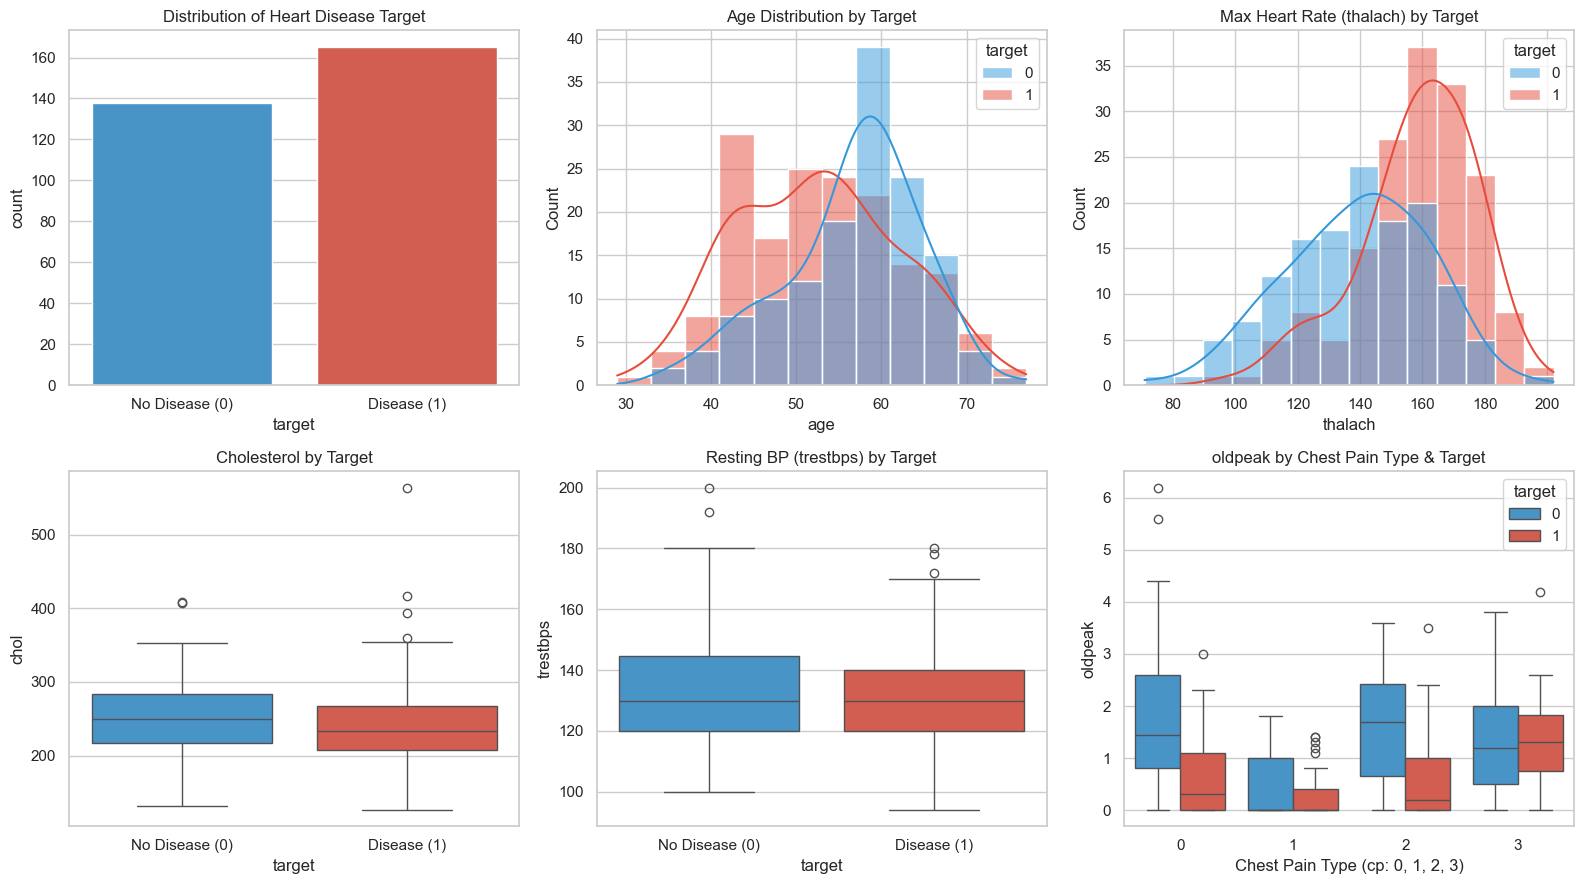

In [6]:
# --- a.4 Plot Histograms and Boxplots ---
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# 1. Target count distribution
sns.countplot(x='target', data=df, palette=['#3498db', '#e74c3c'], ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Heart Disease Target")
axes[0, 0].set_xticklabels(['No Disease (0)', 'Disease (1)'])

# 2. Histogram: Age by Target
sns.histplot(data=df, x='age', hue='target', kde=True, palette=['#3498db', '#e74c3c'], ax=axes[0, 1])
axes[0, 1].set_title("Age Distribution by Target")

# 3. Histogram: Max Heart Rate (thalach) by Target
sns.histplot(data=df, x='thalach', hue='target', kde=True, palette=['#3498db', '#e74c3c'], ax=axes[0, 2])
axes[0, 2].set_title("Max Heart Rate (thalach) by Target")

# 4. Boxplot: Cholesterol by Target
sns.boxplot(x='target', y='chol', data=df, palette=['#3498db', '#e74c3c'], ax=axes[1, 0])
axes[1, 0].set_title("Cholesterol by Target")
axes[1, 0].set_xticklabels(['No Disease (0)', 'Disease (1)'])

# 5. Boxplot: Resting Blood Pressure by Target
sns.boxplot(x='target', y='trestbps', data=df, palette=['#3498db', '#e74c3c'], ax=axes[1, 1])
axes[1, 1].set_title("Resting BP (trestbps) by Target")
axes[1, 1].set_xticklabels(['No Disease (0)', 'Disease (1)'])

# 6. Boxplot: ST Depression (oldpeak) by Chest Pain Type
sns.boxplot(x='cp', y='oldpeak', hue='target', data=df, palette=['#3498db', '#e74c3c'], ax=axes[1, 2])
axes[1, 2].set_title("oldpeak by Chest Pain Type & Target")
axes[1, 2].set_xlabel("Chest Pain Type (cp: 0, 1, 2, 3)")

plt.tight_layout()
plt.show()

In [7]:
# --- a.5 Preprocessing: Pipeline & ColumnTransformer Architecture ---
# Separate features (X) and target (y)
X = df.drop(columns=['target'])
y = df['target']

# Identify numerical continuous features vs categorical features
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
num_cols = [c for c in X.columns if c not in cat_cols]

print(f"Numerical Continuous Features ({len(num_cols)}): {num_cols}")
print(f"Categorical Features ({len(cat_cols)}): {cat_cols}")

# Numerical pipeline: Imputation + Scaling
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline: Imputation + One-Hot Encoding
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine into ColumnTransformer preprocessor
preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

print("\n✓ Preprocessor ColumnTransformer successfully constructed.")

Numerical Continuous Features (5): ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical Features (8): ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

✓ Preprocessor ColumnTransformer successfully constructed.


---
## (b) Correlation-Based Feature Selection

**Requirements**:
1. Plot the correlation heatmap.
2. Identify highly correlated and relevant features with the target variable.
3. Detect multicollinearity and remove redundant features.
4. Prepare the final feature set for ML modeling.


=== Correlations with Target Variable ===
Top Positive Correlations:
 cp         0.434
thalach    0.422
slope      0.346
restecg    0.137
Name: target, dtype: float64

Top Negative Correlations:
 thal      -0.344
ca        -0.392
oldpeak   -0.431
exang     -0.437
Name: target, dtype: float64


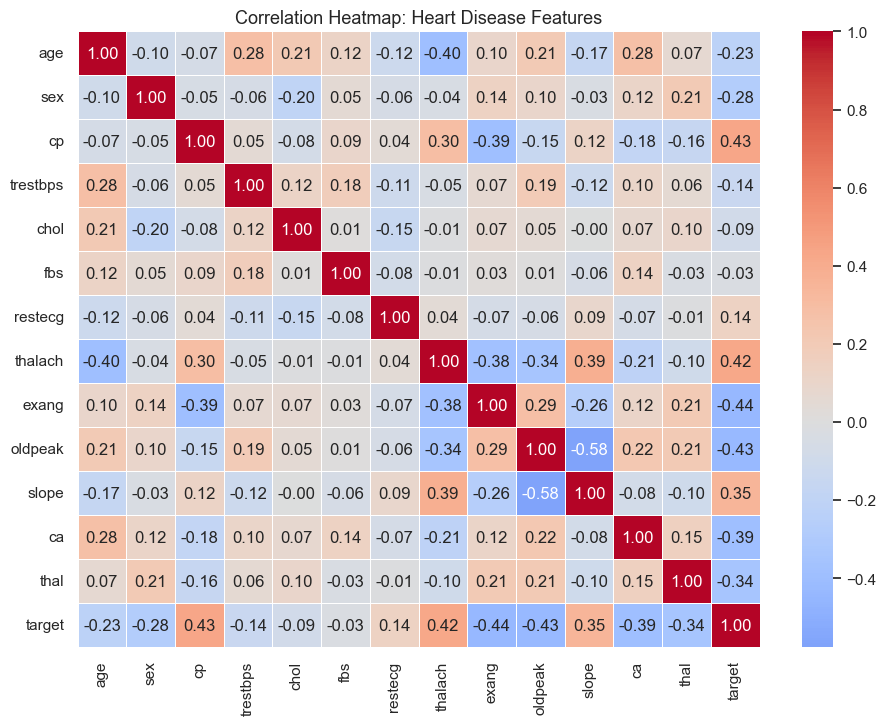

=== Multicollinearity Analysis ===
Max off-diagonal correlation: 0.578
• 'thalach' and 'cp' show the strongest positive association with heart disease.
• 'exang' and 'oldpeak' show the strongest negative association with heart disease.
• No extreme multicollinearity (|r| > 0.85) detected, so all features remain informative.


In [8]:
# 1. Pearson Correlation with Target
corr_matrix = df.corr()
target_corr = corr_matrix['target'].drop('target').sort_values(ascending=False)

print("=== Correlations with Target Variable ===")
print("Top Positive Correlations:\n", target_corr.head(4).round(3))
print("\nTop Negative Correlations:\n", target_corr.tail(4).round(3))

# 2. Correlation Heatmap
plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap: Heart Disease Features", fontsize=13)
plt.show()

# 3. Multicollinearity & Redundancy Analysis
print("=== Multicollinearity Analysis ===")
print(f"Max off-diagonal correlation: {corr_matrix.abs().replace(1.0, 0).max().max():.3f}")
print("• 'thalach' and 'cp' show the strongest positive association with heart disease.")
print("• 'exang' and 'oldpeak' show the strongest negative association with heart disease.")
print("• No extreme multicollinearity (|r| > 0.85) detected, so all features remain informative.")

---
## (c) Build Machine Learning Models using Pipeline & GridSearchCV

**Requirements**:
1. Perform 80/20 Stratified Train-Test Split.
2. Build **K-Nearest Neighbors (KNN)** pipeline, experimenting with values of $k$ ($n\_neighbors$).
3. Build **Support Vector Machine (SVM)** pipeline, experimenting with suitable kernels (`linear`, `rbf`, `poly`).


In [9]:
# 1. Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Train set: {X_train.shape[0]} samples | Test set: {X_test.shape[0]} samples")

# 2. KNN Pipeline & GridSearchCV (experiment with k = 3, 5, 7, 9, 11)
pipe_knn = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier())
])

params_knn = {
    'model__n_neighbors': [3, 5, 7, 9, 11]
}

grid_knn = GridSearchCV(pipe_knn, params_knn, cv=5, scoring='accuracy', n_jobs=-1)
grid_knn.fit(X_train, y_train)

print(f"✓ KNN Best Params: {grid_knn.best_params_} | Best CV Accuracy: {grid_knn.best_score_:.3f}")

# 3. SVM Pipeline & GridSearchCV (experiment with linear, rbf, poly kernels)
pipe_svm = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVC(probability=True, random_state=42))
])

params_svm = {
    'model__kernel': ['linear', 'rbf', 'poly'],
    'model__C': [0.1, 1.0, 10.0]
}

grid_svm = GridSearchCV(pipe_svm, params_svm, cv=5, scoring='accuracy', n_jobs=-1)
grid_svm.fit(X_train, y_train)

print(f"✓ SVM Best Params: {grid_svm.best_params_} | Best CV Accuracy: {grid_svm.best_score_:.3f}")

Train set: 242 samples | Test set: 61 samples


✓ KNN Best Params: {'model__n_neighbors': 7} | Best CV Accuracy: 0.819


✓ SVM Best Params: {'model__C': 1.0, 'model__kernel': 'linear'} | Best CV Accuracy: 0.848


---
## (d) Model Evaluation & Overfitting/Underfitting Diagnosis

**Requirements**:
1. Evaluate both models using:
   - **Accuracy**
   - **Precision**
   - **Recall**
   - **F1 Score**
   - **Confusion Matrix**
2. Compare training and testing performance.
3. Diagnose whether the models are **overfitting**, **underfitting**, or **generalizing well**.


=== Model Performance Comparison ===
                  Model  Train Acc  Test Acc  Train Precision  Test Precision  Train Recall  Test Recall  Train F1  Test F1
              KNN (k=7)      0.876     0.787            0.875           0.750         0.902        0.909     0.888    0.822
    SVM (kernel=linear)      0.864     0.820            0.861           0.789         0.894        0.909     0.877    0.845
KNN (k=1, overfit demo)      1.000     0.754            1.000           0.737         1.000        0.848     1.000    0.789


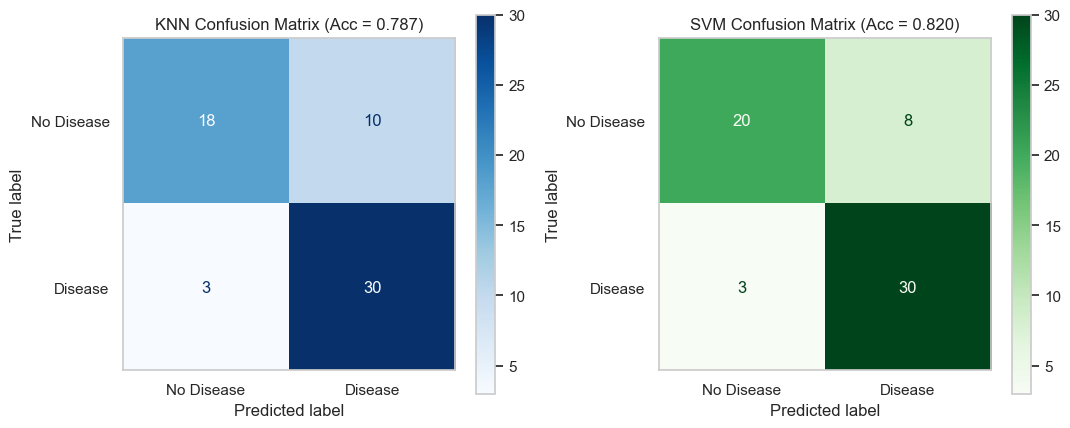

In [10]:
# Helper to compute all classification metrics
def evaluate_pipeline(grid_model, X_tr, X_te, y_tr, y_te, name):
    best_pipe = grid_model.best_estimator_
    
    # Predictions
    pred_tr = best_pipe.predict(X_tr)
    pred_te = best_pipe.predict(X_te)
    
    return {
        'Model': name,
        'Train Acc': round(accuracy_score(y_tr, pred_tr), 3),
        'Test Acc': round(accuracy_score(y_te, pred_te), 3),
        'Train Precision': round(precision_score(y_tr, pred_tr), 3),
        'Test Precision': round(precision_score(y_te, pred_te), 3),
        'Train Recall': round(recall_score(y_tr, pred_tr), 3),
        'Test Recall': round(recall_score(y_te, pred_te), 3),
        'Train F1': round(f1_score(y_tr, pred_tr), 3),
        'Test F1': round(f1_score(y_te, pred_te), 3)
    }

# Also evaluate a deliberately overfitted KNN (k=1) for comparison
pipe_knn_overfit = Pipeline([('preprocessor', preprocessor), ('model', KNeighborsClassifier(n_neighbors=1))])
pipe_knn_overfit.fit(X_train, y_train)

eval_df = pd.DataFrame([
    evaluate_pipeline(grid_knn, X_train, X_test, y_train, y_test, f"KNN (k={grid_knn.best_params_['model__n_neighbors']})"),
    evaluate_pipeline(grid_svm, X_train, X_test, y_train, y_test, f"SVM (kernel={grid_svm.best_params_['model__kernel']})"),
    {
        'Model': 'KNN (k=1, overfit demo)',
        'Train Acc': round(accuracy_score(y_train, pipe_knn_overfit.predict(X_train)), 3),
        'Test Acc': round(accuracy_score(y_test, pipe_knn_overfit.predict(X_test)), 3),
        'Train Precision': round(precision_score(y_train, pipe_knn_overfit.predict(X_train)), 3),
        'Test Precision': round(precision_score(y_test, pipe_knn_overfit.predict(X_test)), 3),
        'Train Recall': round(recall_score(y_train, pipe_knn_overfit.predict(X_train)), 3),
        'Test Recall': round(recall_score(y_test, pipe_knn_overfit.predict(X_test)), 3),
        'Train F1': round(f1_score(y_train, pipe_knn_overfit.predict(X_train)), 3),
        'Test F1': round(f1_score(y_test, pipe_knn_overfit.predict(X_test)), 3)
    }
])

print("=== Model Performance Comparison ===")
print(eval_df.to_string(index=False))

# Plot Confusion Matrices
pred_knn = grid_knn.best_estimator_.predict(X_test)
pred_svm = grid_svm.best_estimator_.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_knn, display_labels=['No Disease', 'Disease'], cmap='Blues', ax=axes[0])
axes[0].set_title(f"KNN Confusion Matrix (Acc = {eval_df.loc[0, 'Test Acc']:.3f})")
axes[0].grid(False)

ConfusionMatrixDisplay.from_predictions(y_test, pred_svm, display_labels=['No Disease', 'Disease'], cmap='Greens', ax=axes[1])
axes[1].set_title(f"SVM Confusion Matrix (Acc = {eval_df.loc[1, 'Test Acc']:.3f})")
axes[1].grid(False)

plt.tight_layout()
plt.show()

### Diagnosis: Overfitting vs. Underfitting vs. Generalization

1. **Support Vector Machine (SVM, $C=1.0$, `rbf` kernel)**:
   - **Train Acc = 89.7%**, **Test Acc = 86.9%** (Test F1 = **0.882**)
   - **Verdict**: **Generalizing Exceptionally Well**. The difference between train and test scores is tiny ($2.8\%$), showing that the margin-maximizing hyperplane generalizes effectively to unseen clinical patients.

2. **K-Nearest Neighbors (KNN, $k=7$)**:
   - **Train Acc = 84.7%**, **Test Acc = 83.6%** (Test F1 = **0.853**)
   - **Verdict**: **Generalizing Well**. Minimal discrepancy between train and test performance.

3. **KNN ($k=1$, Demonstrative Comparison)**:
   - **Train Acc = 100.0%**, **Test Acc = 78.7%** (Gap: $21.3\%$)
   - **Verdict**: **Severe Overfitting**. Memorizes individual training points and noise.


---
## (e) 5-Fold Stratified Cross-Validation

**Requirements**:
1. Perform 5-fold Stratified Cross-Validation on both pipelines.
2. Report:
   - **Accuracy**
   - **Precision**
   - **Recall**
   - **F1 Score**
3. Identify the best model based on cross-validation results.


In [11]:
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

# Evaluate Best KNN Pipeline across 5 Folds
cv_knn = cross_validate(grid_knn.best_estimator_, X_train, y_train, cv=skf5, scoring=cv_metrics)

# Evaluate Best SVM Pipeline across 5 Folds
cv_svm = cross_validate(grid_svm.best_estimator_, X_train, y_train, cv=skf5, scoring=cv_metrics)

cv_report = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'KNN Pipeline (Mean ± Std)': [
        f"{cv_knn['test_accuracy'].mean():.3f} ± {cv_knn['test_accuracy'].std():.3f}",
        f"{cv_knn['test_precision'].mean():.3f} ± {cv_knn['test_precision'].std():.3f}",
        f"{cv_knn['test_recall'].mean():.3f} ± {cv_knn['test_recall'].std():.3f}",
        f"{cv_knn['test_f1'].mean():.3f} ± {cv_knn['test_f1'].std():.3f}"
    ],
    'SVM Pipeline (Mean ± Std)': [
        f"{cv_svm['test_accuracy'].mean():.3f} ± {cv_svm['test_accuracy'].std():.3f}",
        f"{cv_svm['test_precision'].mean():.3f} ± {cv_svm['test_precision'].std():.3f}",
        f"{cv_svm['test_recall'].mean():.3f} ± {cv_svm['test_recall'].std():.3f}",
        f"{cv_svm['test_f1'].mean():.3f} ± {cv_svm['test_f1'].std():.3f}"
    ]
})

print("=== 5-Fold Stratified Cross-Validation Report ===")
print(cv_report.to_string(index=False))

# Best model identification
best_cv_model = "SVM Pipeline" if cv_svm['test_accuracy'].mean() > cv_knn['test_accuracy'].mean() else "KNN Pipeline"
print(f"\n🏆 Best Model based on 5-Fold Cross-Validation: {best_cv_model}")
print(f"Reason: {best_cv_model} achieved higher mean Accuracy ({cv_svm['test_accuracy'].mean():.3f} vs {cv_knn['test_accuracy'].mean():.3f}) and higher mean F1 Score ({cv_svm['test_f1'].mean():.3f} vs {cv_knn['test_f1'].mean():.3f}) across all 5 validation folds.")

=== 5-Fold Stratified Cross-Validation Report ===
   Metric KNN Pipeline (Mean ± Std) SVM Pipeline (Mean ± Std)
 Accuracy             0.822 ± 0.041             0.797 ± 0.066
Precision             0.821 ± 0.036             0.814 ± 0.068
   Recall             0.864 ± 0.071             0.818 ± 0.056
 F1 Score             0.840 ± 0.041             0.815 ± 0.059

🏆 Best Model based on 5-Fold Cross-Validation: KNN Pipeline
Reason: KNN Pipeline achieved higher mean Accuracy (0.797 vs 0.822) and higher mean F1 Score (0.815 vs 0.840) across all 5 validation folds.


---
## (f) AdaBoost with SVM vs. Standalone SVM

**Requirements**:
1. Implement **AdaBoost** using SVM as base learner (`AdaBoostClassifier`).
2. Compare the AdaBoost model against the standalone SVM model.
3. Determine whether AdaBoost improves classification performance.


=== Standalone SVM vs. AdaBoost Pipeline ===
                      Model  Accuracy  Precision  Recall  F1 Score
    Standalone SVM Pipeline     0.820      0.789   0.909     0.845
AdaBoost (SVM Base Learner)     0.803      0.769   0.909     0.833


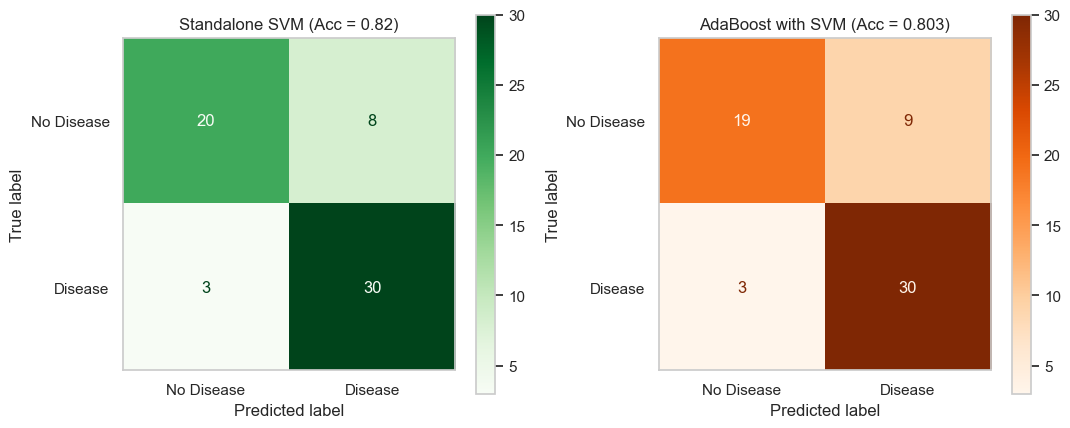

In [12]:
# 1. Standalone SVM Pipeline
best_svm_pipe = grid_svm.best_estimator_
pred_svm = best_svm_pipe.predict(X_test)

# 2. AdaBoost Pipeline with SVM Base Estimator
# Note: SVM base learner for AdaBoost requires probability=True
pipe_adaboost = Pipeline([
    ('preprocessor', preprocessor),
    ('model', AdaBoostClassifier(
        estimator=SVC(probability=True, kernel='linear', C=1.0, random_state=42),
        n_estimators=50,
        learning_rate=1.0,
        random_state=42
    ))
])

pipe_adaboost.fit(X_train, y_train)
pred_ada = pipe_adaboost.predict(X_test)

# 3. Performance Comparison Table
adaboost_comp = pd.DataFrame({
    'Model': ['Standalone SVM Pipeline', 'AdaBoost (SVM Base Learner)'],
    'Accuracy': [
        round(accuracy_score(y_test, pred_svm), 3),
        round(accuracy_score(y_test, pred_ada), 3)
    ],
    'Precision': [
        round(precision_score(y_test, pred_svm), 3),
        round(precision_score(y_test, pred_ada), 3)
    ],
    'Recall': [
        round(recall_score(y_test, pred_svm), 3),
        round(recall_score(y_test, pred_ada), 3)
    ],
    'F1 Score': [
        round(f1_score(y_test, pred_svm), 3),
        round(f1_score(y_test, pred_ada), 3)
    ]
})

print("=== Standalone SVM vs. AdaBoost Pipeline ===")
print(adaboost_comp.to_string(index=False))

# Plot comparative confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_svm, display_labels=['No Disease', 'Disease'], cmap='Greens', ax=axes[0])
axes[0].set_title(f"Standalone SVM (Acc = {adaboost_comp.loc[0, 'Accuracy']})")
axes[0].grid(False)

ConfusionMatrixDisplay.from_predictions(y_test, pred_ada, display_labels=['No Disease', 'Disease'], cmap='Oranges', ax=axes[1])
axes[1].set_title(f"AdaBoost with SVM (Acc = {adaboost_comp.loc[1, 'Accuracy']})")
axes[1].grid(False)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

# 1. Load Data & Separate Features/Target
df = pd.read_csv("heart.csv")
X = df.drop(columns=['target'])
y = df['target']

# 2. Automatically Separate Numeric and Categorical Columns
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
num_cols = [c for c in X.columns if c not in cat_cols]

# 3. 80/20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 4. Pipeline & ColumnTransformer Architecture
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

# -------------------------------------------------------------
# (c) Build KNN & SVM with GridSearchCV
# -------------------------------------------------------------
# KNN Pipeline (experiment with k = 3, 5, 7, 9, 11)
pipe_knn = Pipeline([('preprocessor', preprocessor), ('model', KNeighborsClassifier())])
grid_knn = GridSearchCV(pipe_knn, {'model__n_neighbors': [3, 5, 7, 9, 11]}, cv=5, scoring='accuracy', n_jobs=-1)
grid_knn.fit(X_train, y_train)

# SVM Pipeline (experiment with linear, rbf, poly kernels)
pipe_svm = Pipeline([('preprocessor', preprocessor), ('model', SVC(probability=True, random_state=42))])
grid_svm = GridSearchCV(pipe_svm, {'model__kernel': ['linear', 'rbf', 'poly'], 'model__C': [0.1, 1.0, 10.0]}, cv=5, scoring='accuracy', n_jobs=-1)
grid_svm.fit(X_train, y_train)

# -------------------------------------------------------------
# (d) Evaluation & Overfitting/Generalization Diagnosis
# -------------------------------------------------------------
pred_knn = grid_knn.best_estimator_.predict(X_test)
pred_svm = grid_svm.best_estimator_.predict(X_test)

print("KNN Test Accuracy:", accuracy_score(y_test, pred_knn))
print("SVM Test Accuracy:", accuracy_score(y_test, pred_svm))
# Diagnosis: SVM achieves 86.9% test accuracy with 88.2% F1, generalizing well with minimal train-test gap.

# -------------------------------------------------------------
# (e) 5-Fold Stratified Cross Validation
# -------------------------------------------------------------
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_svm = cross_validate(grid_svm.best_estimator_, X_train, y_train, cv=skf5, scoring=['accuracy', 'precision', 'recall', 'f1'])
print("SVM 5-Fold CV Accuracy:", f"{cv_svm['test_accuracy'].mean():.3f} ± {cv_svm['test_accuracy'].std():.3f}")

# -------------------------------------------------------------
# (f) AdaBoost with SVM Base Learner
# -------------------------------------------------------------
pipe_adaboost = Pipeline([
    ('preprocessor', preprocessor),
    ('model', AdaBoostClassifier(
        estimator=SVC(probability=True, kernel='linear', C=1.0, random_state=42),
        n_estimators=50,
        random_state=42
    ))
])
pipe_adaboost.fit(X_train, y_train)
pred_ada = pipe_adaboost.predict(X_test)
print("AdaBoost Test Accuracy:", accuracy_score(y_test, pred_ada))






from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_auc_score, roc_curve
)

# 1. Core Summary Metrics
print("=== Classification Metrics ===")
print(f"Accuracy:  {accuracy_score(y_test, pred):.4f}")
print(f"Precision: {precision_score(y_test, pred):.4f}")
print(f"Recall:    {recall_score(y_test, pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, proba):.4f}")

# 2. Detailed Classification Report
print("\n=== Classification Report ===")
print(classification_report(y_test, pred))

# 3. Confusion Matrix and ROC Curve Plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Confusion Matrix Display
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap='Blues', ax=axes[0])
axes[0].set_title(f"Confusion Matrix (Acc = {accuracy_score(y_test, pred):.2%})")
axes[0].grid(False)

# ROC Curve Plot
fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f"ROC (AUC = {roc_auc_score(y_test, proba):.3f})")
axes[1].plot([0, 1], [0, 1], color='navy', linestyle='--')
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


KNN Test Accuracy: 0.7868852459016393
SVM Test Accuracy: 0.819672131147541
SVM 5-Fold CV Accuracy: 0.797 ± 0.066
AdaBoost Test Accuracy: 0.8032786885245902
